# EN3160 - Assignment 02
## Fitting and Alignment

**Name:** Bandara H.Y.W.  
**Index Number:** 230074J  
**GitHub:** https://github.com/YohanBandara/Computer-Vision

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from skimage.feature import blob_log

## Question 1 - Blob Detection

Number of blobs: 129
Sigma range: 1.5 to 10


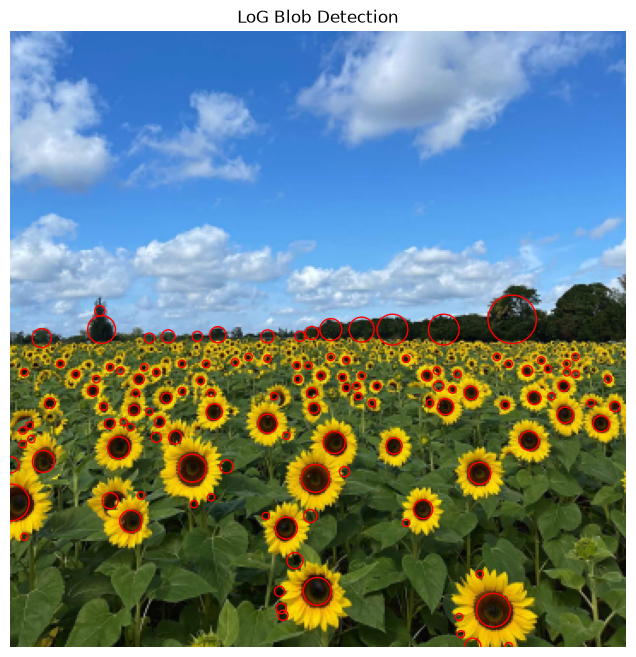

Largest detected circles:
1: center=(293.0, 168.0), sigma=10.00, radius=14.14
2: center=(0.0, 275.0), sigma=7.57, radius=10.71
3: center=(282.0, 338.0), sigma=6.96, radius=9.85
4: center=(223.0, 174.0), sigma=6.36, radius=8.99
5: center=(253.0, 174.0), sigma=6.36, radius=8.99
6: center=(106.0, 255.0), sigma=5.75, radius=8.13
7: center=(178.0, 261.0), sigma=5.75, radius=8.13
8: center=(179.0, 327.0), sigma=5.75, radius=8.13
9: center=(53.0, 174.0), sigma=5.75, radius=8.13
10: center=(205.0, 174.0), sigma=5.14, radius=7.27


In [9]:
image_path = "a2images/the_berry_farms_sunflower_field.jpeg"

im = cv.imread(image_path, cv.IMREAD_REDUCED_COLOR_4)

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
gray = gray.astype(np.float32) / 255.0

gray_inv = 1 - gray

min_sigma = 1.5
max_sigma = 10
num_sigma = 15

blobs = blob_log(
    gray_inv,
    min_sigma=min_sigma,
    max_sigma=max_sigma,
    num_sigma=num_sigma,
    threshold=0.20,
    overlap=0.5
)

h = im.shape[0]
blobs = [b for b in blobs if b[0] > 0.45 * h]


blobs = np.array(blobs)

if len(blobs) > 0:
    blobs[:, 2] = blobs[:, 2] * np.sqrt(2)

print("Number of blobs:", len(blobs))
print("Sigma range:", min_sigma, "to", max_sigma)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for y, x, r in blobs:
    circle = plt.Circle(
        (x, y),
        r,
        fill=False,
        linewidth=1,
        color="red"
    )
    ax.add_patch(circle)

ax.set_title("LoG Blob Detection")
ax.axis("off")

plt.show()


largest = sorted(blobs, key=lambda x: x[2], reverse=True)

print("Largest detected circles:")

for i, (y, x, r) in enumerate(largest[:10]):
    sigma = r / np.sqrt(2)

    print(
        f"{i+1}: center=({x:.1f}, {y:.1f}), "
        f"sigma={sigma:.2f}, radius={r:.2f}"
    )

### Observation

The sunflower centers are dark, so I inverted the grayscale image before applying LoG.
For a LoG blob, the approximate radius is:
r = sqrt{2} *sigma
The sigma range used was 1.5 to 10.

The larger circles are mainly detected on the sunflowers closer to the camera. Smaller circles are found on the flowers further away.
A few incorrect blobs can also occur because other image regions may have a similar dark circular pattern.

## Question 2 - Line and Circle Fitting

Line inliers: 40
Best-fit line: a = 0.717, b = 0.697, d = 1.445
Circle inliers: 48
Best-fit circle center = (1.933, 3.108)
Best-fit circle radius = 9.848


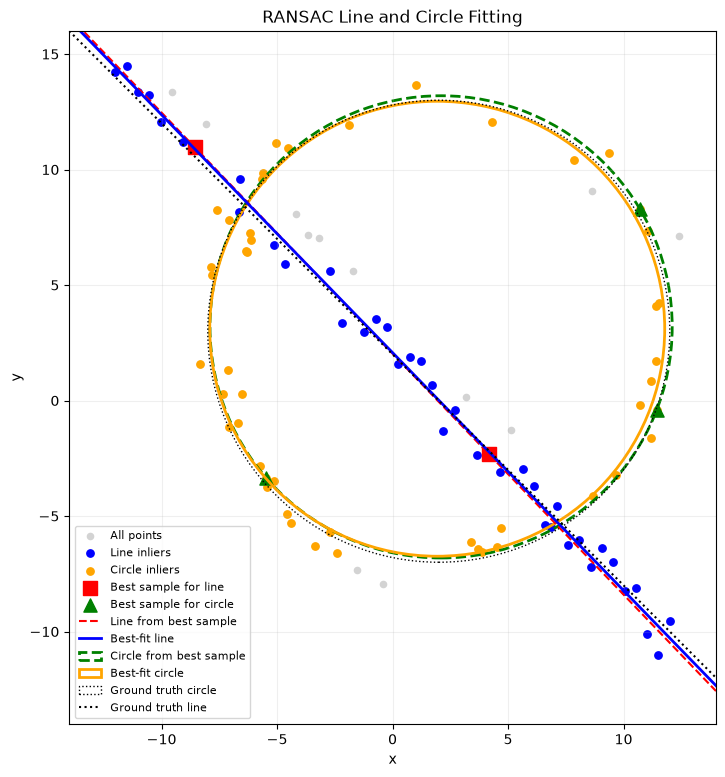

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Generate the noisy point set given in the assignment
np.random.seed(0)
N = 100
half_n = N // 2

r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s * np.random.randn(half_n)
x = x0_gt + (r+n)*np.cos(t)
y = y0_gt + (r+n)*np.sin(t)
X_circ = np.column_stack((x, y))

s = 1.0
m, c = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + c + s*np.random.randn(half_n)
X_line = np.column_stack((x, y))

X = np.vstack((X_circ, X_line))


#2(a) RANSAC line fitting
line_threshold = 0.75
line_iterations = 2000
best_line_count = 0

for i in range(line_iterations):
    ids = np.random.choice(len(X), 2, replace=False)
    p1, p2 = X[ids]

    v = p2 - p1
    length = np.linalg.norm(v)
    if length == 0:
        continue

    a, b = v[1]/length, -v[0]/length       # unit normal
    d = a*p1[0] + b*p1[1]

    distances = np.abs(a*X[:,0] + b*X[:,1] - d)
    inliers = distances < line_threshold
    count = np.sum(inliers)

    if count > best_line_count:
        best_line_count = count
        best_line_inliers = inliers
        best_line_sample = ids
        best_sample_line = (a, b, d)


line_points = X[best_line_inliers]
centroid = np.mean(line_points, axis=0)
_, _, Vt = np.linalg.svd(line_points - centroid)
normal = Vt[-1] / np.linalg.norm(Vt[-1])
a_fit, b_fit = normal
d_fit = np.dot(normal, centroid)


#2(b) Remove line and fit circle using RANSAC
X_remain = X[~best_line_inliers]

def circle_from_3_points(p1, p2, p3):
    A = np.array([[2*(p2[0]-p1[0]), 2*(p2[1]-p1[1])],
                  [2*(p3[0]-p1[0]), 2*(p3[1]-p1[1])]])

    B = np.array([p2[0]**2+p2[1]**2-p1[0]**2-p1[1]**2,
                  p3[0]**2+p3[1]**2-p1[0]**2-p1[1]**2])

    if abs(np.linalg.det(A)) < 1e-10:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(p1-center)
    return center[0], center[1], radius


circle_threshold = 1.0
circle_iterations = 3000
best_circle_count = 0

for i in range(circle_iterations):
    ids = np.random.choice(len(X_remain), 3, replace=False)
    circle = circle_from_3_points(*X_remain[ids])

    if circle is None:
        continue

    cx, cy, radius = circle
    distances = np.sqrt((X_remain[:,0]-cx)**2 + (X_remain[:,1]-cy)**2)
    errors = np.abs(distances-radius)

    inliers = errors < circle_threshold
    count = np.sum(inliers)

    if count > best_circle_count:
        best_circle_count = count
        best_circle_inliers = inliers
        best_circle_sample = ids
        best_sample_circle = circle


circle_points = X_remain[best_circle_inliers]

def circle_error(params):
    cx, cy, radius = params
    distances = np.sqrt((circle_points[:,0]-cx)**2 + (circle_points[:,1]-cy)**2)
    return np.sum((distances-radius)**2)

result = minimize(circle_error, best_sample_circle)
cx_fit, cy_fit, r_fit = result.x

print("Line inliers:", best_line_count)
print(f"Best-fit line: a = {a_fit:.3f}, b = {b_fit:.3f}, d = {d_fit:.3f}")
print("Circle inliers:", best_circle_count)
print(f"Best-fit circle center = ({cx_fit:.3f}, {cy_fit:.3f})")
print(f"Best-fit circle radius = {r_fit:.3f}")


#2(c)plotting 
fig, ax = plt.subplots(figsize=(9,9))

ax.scatter(X[:,0], X[:,1], s=20, color='lightgray', label='All points')
ax.scatter(X[best_line_inliers,0], X[best_line_inliers,1], s=28, color='blue', label='Line inliers')
ax.scatter(X_remain[best_circle_inliers,0], X_remain[best_circle_inliers,1], s=28, color='orange', label='Circle inliers')

line_sample_points = X[best_line_sample]
circle_sample_points = X_remain[best_circle_sample]

ax.scatter(line_sample_points[:,0], line_sample_points[:,1], marker='s', s=90, color='red', label='Best sample for line')
ax.scatter(circle_sample_points[:,0], circle_sample_points[:,1], marker='^', s=90, color='green', label='Best sample for circle')

x_plot = np.linspace(-14, 14, 300)

a_s, b_s, d_s = best_sample_line
ax.plot(x_plot, (d_s-a_s*x_plot)/b_s, '--', color='red', label='Line from best sample')
ax.plot(x_plot, (d_fit-a_fit*x_plot)/b_fit, color='blue', linewidth=2, label='Best-fit line')

cx_s, cy_s, r_s = best_sample_circle
ax.add_patch(plt.Circle((cx_s,cy_s), r_s, fill=False, linestyle='--', color='green', linewidth=2, label='Circle from best sample'))
ax.add_patch(plt.Circle((cx_fit,cy_fit), r_fit, fill=False, color='orange', linewidth=2, label='Best-fit circle'))

ax.add_patch(plt.Circle((x0_gt,y0_gt), r, fill=False, linestyle=':', color='black', label='Ground truth circle'))
ax.plot(x_plot, m*x_plot+c, ':', color='black', label='Ground truth line')

ax.set_xlim(-14,14)
ax.set_ylim(-14,16)
ax.set_aspect('equal')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('RANSAC Line and Circle Fitting')
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.show()


## Discussion

### 2(a) Line fitting

RANSAC was first used to estimate the line. Two random points were selected in each iteration to form a line

$$ax + by = d$$

where $[a,b]^T$ was normalized so that

$$\sqrt{a^2+b^2}=1$$

Therefore, the perpendicular distance of a point \((x_i,y_i)\) from the line is

$$|ax_i+by_i-d|$$

Points with an error below the selected threshold were treated as inliers. The model with the largest consensus was selected and the final line was estimated using all of its inliers.

### 2(b) Circle fitting

The inliers belonging to the detected line were removed from the original point set. RANSAC was then applied to the remaining points.

Three points were randomly selected in each iteration to estimate a circle. The radial error was calculated as the difference between the distance from a point to the estimated centre and the estimated radius.

The circle with the largest consensus was selected. Finally, `scipy.optimize.minimize` was used with all detected circle inliers to improve the estimates of the centre and radius.

### 2(c) Results

The plot shows the complete noisy point set together with the line inliers, circle inliers, samples producing the best RANSAC models, models obtained from those samples, and the final best-fit line and circle. The ground-truth line and circle are also shown for comparison.

### 2(d) What happens if the circle is fitted first?

If the circle is fitted first, some points belonging to the line may also be accepted as circle inliers. This can produce an incorrect circle or reduce the accuracy of the estimated circle.

Fitting the line first and removing its consensus reduces this interference and makes the subsequent circle estimation more reliable.

## Question 3 - Image Superimposition using Homography

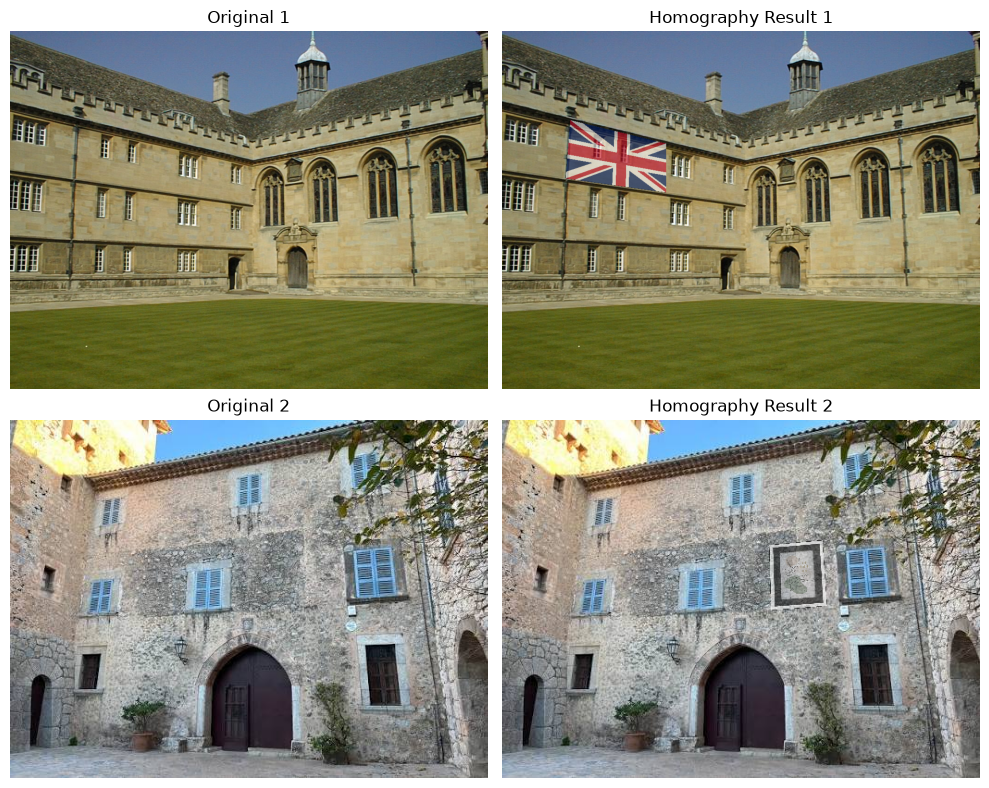

In [47]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def homography(bg_path, img_path, dst):
    bg, img = cv.imread(bg_path), cv.imread(img_path)
    h, w = img.shape[:2]
    src = np.float32([[0,0],[w-1,0],[w-1,h-1],[0,h-1]])
    dst = np.float32(dst)
    H = cv.getPerspectiveTransform(src, dst)
    warped = cv.warpPerspective(img, H, (bg.shape[1],bg.shape[0]))
    mask = np.zeros(bg.shape[:2],dtype=np.uint8); cv.fillConvexPoly(mask,dst.astype(int),255)
    result = bg.copy(); area = mask==255
    result[area] = (0.6*warped[area] + 0.4*bg[area]).astype(np.uint8)
    return bg, result, H

# Pair 1 - Wadham + flag
dst1 = [[145,190],[350,240],[350,345],[135,315]]
bg1, result1, H1 = homography("a2images/wadham.jpg","a2images/flag.png",dst1)

# Pair 2 - Building + artwork (kept upright, no visible rotation)
dst2 = [[288,135],[345,130],[350,200],[290,205]]
bg2, result2, H2 = homography("a2images/homography_testing.jpeg","a2images/homography_testing2.jpeg",dst2)

# Results
fig, ax = plt.subplots(2,2,figsize=(10,8))
ax[0,0].imshow(cv.cvtColor(bg1,cv.COLOR_BGR2RGB)); ax[0,0].set_title("Original 1")
ax[0,1].imshow(cv.cvtColor(result1,cv.COLOR_BGR2RGB)); ax[0,1].set_title("Homography Result 1")
ax[1,0].imshow(cv.cvtColor(bg2,cv.COLOR_BGR2RGB)); ax[1,0].set_title("Original 2")
ax[1,1].imshow(cv.cvtColor(result2,cv.COLOR_BGR2RGB)); ax[1,1].set_title("Homography Result 2")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()






## Result and Discussion

The result shows that a rectangular image can be realistically placed on a surface viewed from a different perspective without manually changing its shape.

For the final experiment, the same method is applied to another image pair of my own choice. Planar surfaces are selected because they provide four clear corner points and allow the inserted image to appear naturally after perspective transformation.

## Question 4 - PCB Image Alignment and Difference Detection

AECC2.jpg - Good matches: 4321  RANSAC inliers: 3846
AECC3.jpg - Good matches: 5629  RANSAC inliers: 5006
AECC4.jpg - Good matches: 3830  RANSAC inliers: 3402
ADAD1.jpg - Good matches: 370  RANSAC inliers: 195
AAAA1.jpg - Good matches: 51  RANSAC inliers: 18


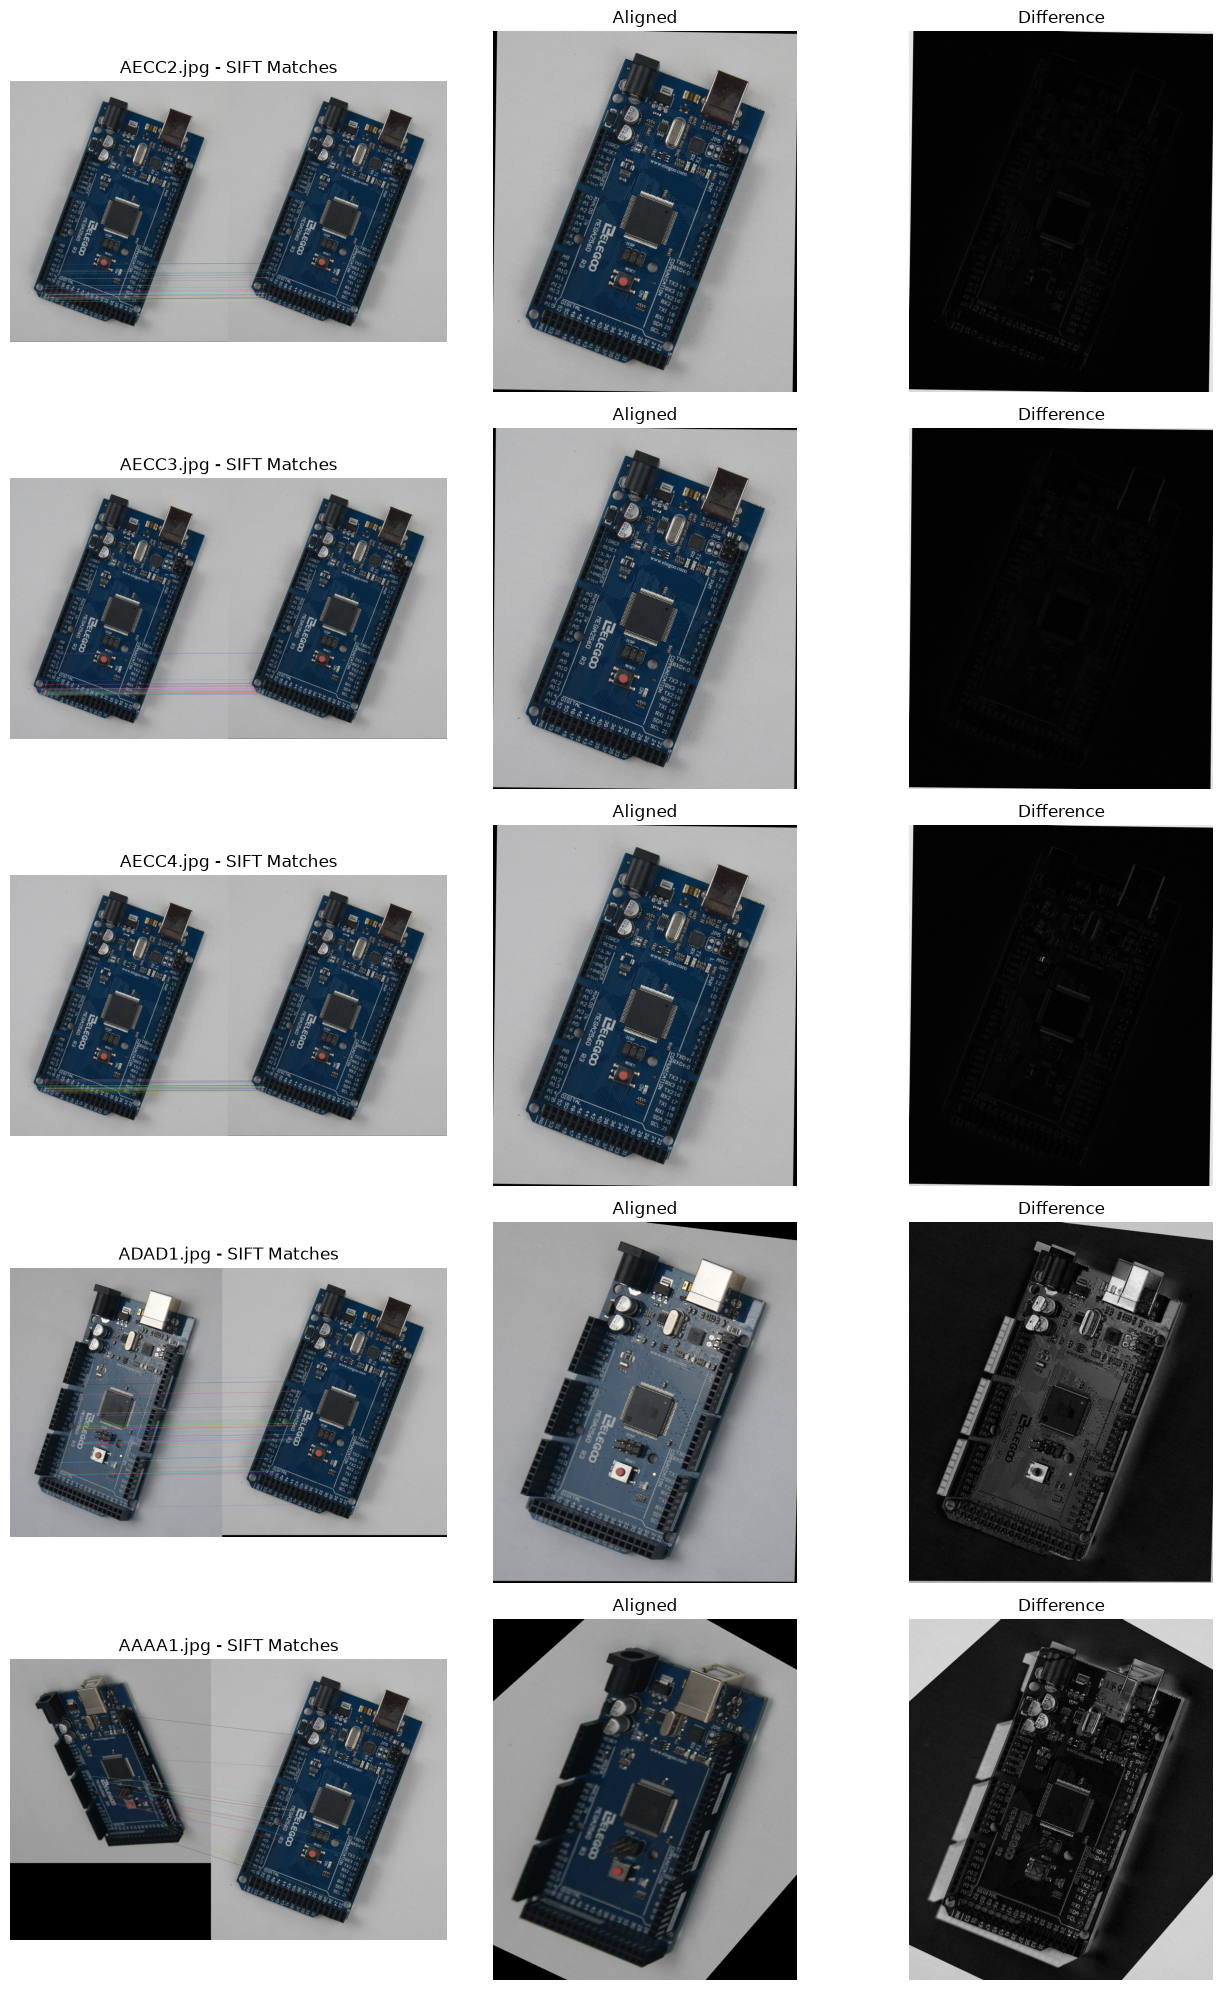

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

path = "a2images/pcbs/"
template = cv.imread(path + "AECC1.jpg")
files = ["AECC2.jpg","AECC3.jpg","AECC4.jpg","ADAD1.jpg","AAAA1.jpg"]

#4(a) SIFT features
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(template, None)
matcher = cv.BFMatcher()

results = []

for name in files:
    img = cv.imread(path + name)
    kp2, des2 = sift.detectAndCompute(img, None)

    # 4(b) Matching and Homography using RANSAC
    matches = matcher.knnMatch(des2, des1, k=2)
    good = [m for m,n in matches if m.distance < 0.75*n.distance]

    src = np.float32([kp2[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    dst = np.float32([kp1[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)

    inliers = [m for m,keep in zip(good,mask.ravel()) if keep]
    match_img = cv.drawMatches(img,kp2,template,kp1,inliers[:40],None,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    # 4(c) Align image and calculating difference
    aligned = cv.warpPerspective(img, H, (template.shape[1],template.shape[0]))
    diff = cv.absdiff(template, aligned)
    diff_gray = cv.cvtColor(diff, cv.COLOR_BGR2GRAY)

    results.append((name, match_img, aligned, diff_gray))
    print(name, "- Good matches:", len(good), " RANSAC inliers:", len(inliers))

# 4(d) Results for all PCB images
fig, ax = plt.subplots(len(results),3,figsize=(13,4*len(results)))
for i,(name,matches,aligned,diff) in enumerate(results):
    ax[i,0].imshow(cv.cvtColor(matches,cv.COLOR_BGR2RGB)); ax[i,0].set_title(name+" - SIFT Matches")
    ax[i,1].imshow(cv.cvtColor(aligned,cv.COLOR_BGR2RGB)); ax[i,1].set_title("Aligned")
    ax[i,2].imshow(diff,cmap="gray"); ax[i,2].set_title("Difference")
    for j in range(3): ax[i,j].axis("off")

plt.tight_layout()
plt.show()

## Results and Discussion

### 4(a) SIFT Feature Detection
SIFT keypoints and descriptors were detected in the reference image `AECC1.jpg` and in each PCB image. These features provide distinctive points that can be used for image matching.

### 4(b) Feature Matching and Homography
The SIFT descriptors were matched using `BFMatcher`. Poor matches were removed using the ratio test, and the remaining corresponding points were used to estimate a homography using RANSAC. The matched features were also displayed between the two images.

### 4(c) Image Alignment and Difference
Each PCB image was warped using the estimated homography so that it aligned with the reference image. The absolute difference between the aligned PCB and `AECC1.jpg` was then calculated. Dark areas indicate similar regions, while brighter areas indicate larger differences.

### 4(d) Results for All PCB Images
The same procedure was applied to all the provided PCB images. The results show that the planar PCB regions can be aligned well using the homography, while some components and regions still show noticeable differences due to changes in viewpoint, lighting and the three-dimensional structure of the components.